# ChequeGen — Overcoming the Slow-Sampling Limitation of Diffusion Models (DDPM → DDIM)
### Synthetic handwritten cheque-amount generation for privacy-safe banking OCR

**Course:** CAC — Generative Architectures · **Phase 3 & 4:** Implementation, Benchmarking and Deployment · **Version 2 (GPU run, limitations addressed)**

---

## Project overview

| Item | Description |
|---|---|
| **Problem** | Banks need large labelled handwriting datasets to train cheque-amount OCR (Cheque Truncation System, CTS). Real cheques cannot be shared because they contain customer data. |
| **Architecture chosen** | Denoising Diffusion Probabilistic Model (DDPM) — best sample quality and diversity of the four architectures studied (Transformer, GAN, VAE, Diffusion). |
| **Limitation tackled** | **Slow sampling.** DDPM needs T = 1000 sequential denoising passes to generate one image. |
| **Proposed fix** | (1) **DDIM** — a non-Markovian reverse process that skips steps (1000 → 50/20/10) using the *same* trained network. (2) **Class-conditioning + classifier-free guidance (CFG)** so any digit, and therefore any amount, can be generated on demand. |
| **v2: limitations addressed** | (a) **Compute:** larger U-Net trained 4× longer on GPU with mixed precision. (b) **Evaluation reliability:** 4× more samples, several random seeds (mean ± std), plus **precision/recall** to measure quality and diversity separately. (c) **Even faster sampling:** **DPM-Solver++(2M)**, a 2nd-order ODE solver, at 5–20 steps. (d) **Diversity gap:** guidance-weight sweep chosen by OCR accuracy. (e) **Practical use:** synthetic data as *augmentation* for a small real dataset. |
| **Dataset** | MNIST — 70,000 handwritten digits (28×28, labels 0–9), a public, privacy-free stand-in for cheque digits. |
| **Metrics** | Inference latency (ms/image), FID (Fréchet distance on features of an MNIST classifier), **precision** (realism) and **recall** (diversity), label accuracy of generated digits, and OCR usefulness (train a digit reader on synthetic data, test on real digits). |
| **Demo** | Type an amount → ChequeGen writes it in handwriting on a *SPECIMEN* cheque (Gradio app, `app.py`). |

**Notebook flow:** setup → data → noise schedule → conditional U-Net → training → samplers (DDPM baseline, DDIM, DPM-Solver++) → benchmark over several seeds → diversity limitation and guidance sweep → synthetic data as augmentation → cheque demo → summary.

> **All interpretation text after an experiment is generated from the numbers of that run**, so it stays correct whichever hardware the notebook runs on.

## 1. Setup and configuration

All hyper-parameters live in one `CFG` dictionary. The notebook adapts to the hardware it runs on:

* **GPU (local NVIDIA GPU or Colab):** U-Net with 64-128-256 channels (≈ 3.7 M parameters), 20,000 training steps at batch 256 with mixed precision (fp16), 2,000 images × 3 seeds per sampler.
* **CPU fallback:** U-Net with 16-32-64 channels, 5,000 steps, 500 images × 2 seeds, so the notebook still finishes on a laptop without a GPU.

If a checkpoint trained with the same settings already exists in `checkpoints/`, training is skipped and the checkpoint is reused.

In [1]:
import os, gzip, json, time, math, random, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import linalg

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SMOKE = os.environ.get('CHEQUEGEN_SMOKE') == '1'      # tiny run used only to test the notebook end-to-end
if DEVICE == 'cpu':
    torch.set_num_threads(os.cpu_count())

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(42)

GPU = DEVICE == 'cuda'
CFG = dict(
    T=1000, beta_start=1e-4, beta_end=0.02,           # linear noise schedule of Ho et al. (2020)
    channels=(64, 128, 256) if GPU else (16, 32, 64), # U-Net width
    batch_size=256 if GPU else 128,
    lr=5e-4 if GPU else 1e-3, warmup=500 if GPU else 200,
    train_steps=30 if SMOKE else (20000 if GPU else 5000),
    ema_decay=0.9995 if GPU else 0.999,
    amp=GPU,                                          # mixed-precision (fp16) training and sampling on GPU
    p_uncond=0.1,                                     # label dropout for classifier-free guidance
    guidance=1.5,                                     # CFG weight w used in the main benchmark
    n_eval=40 if SMOKE else (2000 if GPU else 500),   # images per sampler and seed
    n_seeds=2 if (SMOKE or not GPU) else 3,           # repeat every measurement with different seeds
    sample_batch=500 if GPU else 250,
    n_synth_per_class=20 if SMOKE else (500 if GPU else 300),
    guidance_sweep=[0.0, 0.5, 1.0, 1.5, 3.0],         # limitation study: diversity vs guidance
    low_real_per_class=10 if SMOKE else 50,           # small real dataset for the augmentation study
)
if GPU:
    torch.backends.cudnn.benchmark = True
    print('GPU:', torch.cuda.get_device_name(0))
os.makedirs('figures', exist_ok=True); os.makedirs('checkpoints', exist_ok=True)
print('Device:', DEVICE, '| smoke test:', SMOKE)
print(json.dumps(CFG, indent=1))

GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Device: cuda | smoke test: False
{
 "T": 1000,
 "beta_start": 0.0001,
 "beta_end": 0.02,
 "channels": [
  64,
  128,
  256
 ],
 "batch_size": 256,
 "lr": 0.0005,
 "warmup": 500,
 "train_steps": 20000,
 "ema_decay": 0.9995,
 "amp": true,
 "p_uncond": 0.1,
 "guidance": 1.5,
 "n_eval": 2000,
 "n_seeds": 3,
 "sample_batch": 500,
 "n_synth_per_class": 500,
 "guidance_sweep": [
  0.0,
  0.5,
  1.0,
  1.5,
  3.0
 ],
 "low_real_per_class": 50
}


## 2. Dataset — MNIST handwritten digits

MNIST is read straight from its original IDX files (downloaded from a GitHub mirror if missing).
Pixels are scaled from [0, 255] to **[−1, 1]**, the range the diffusion model works in: pure Gaussian noise is then on the same scale as the data.

In [2]:
DATA_DIR = 'data'
MIRROR = 'https://raw.githubusercontent.com/fgnt/mnist/master/'
FILES = dict(train_x='train-images-idx3-ubyte.gz', train_y='train-labels-idx1-ubyte.gz',
             test_x='t10k-images-idx3-ubyte.gz',   test_y='t10k-labels-idx1-ubyte.gz')
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES.values():
    p = os.path.join(DATA_DIR, f)
    if not os.path.exists(p):
        urllib.request.urlretrieve(MIRROR + f, p)

def read_idx(path, offset):
    with gzip.open(path, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=offset)

def to_tensor(imgs):                                  # uint8 [N,28,28] -> float [-1,1] [N,1,28,28]
    return torch.from_numpy(imgs.astype(np.float32) / 127.5 - 1.0).unsqueeze(1)

Xtr = to_tensor(read_idx(os.path.join(DATA_DIR, FILES['train_x']), 16).reshape(-1, 28, 28))
Ytr = torch.from_numpy(read_idx(os.path.join(DATA_DIR, FILES['train_y']), 8).astype(np.int64))
Xte = to_tensor(read_idx(os.path.join(DATA_DIR, FILES['test_x']), 16).reshape(-1, 28, 28))
Yte = torch.from_numpy(read_idx(os.path.join(DATA_DIR, FILES['test_y']), 8).astype(np.int64))
print('train:', tuple(Xtr.shape), ' test:', tuple(Xte.shape), ' pixel range:', Xtr.min().item(), Xtr.max().item())
print('images per class (train):', torch.bincount(Ytr).tolist())

train: (60000, 1, 28, 28)  test: (10000, 1, 28, 28)  pixel range: -1.0 1.0
images per class (train): [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


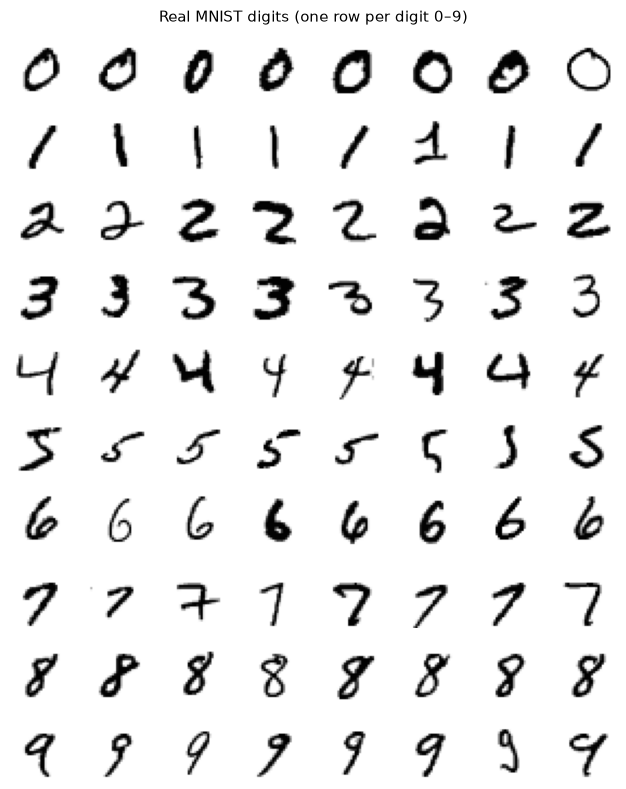

In [3]:
def show_grid(x, nrow, title=None, path=None, figsize=None):
    # x in [-1,1], shape [N,1,28,28]; shown as dark ink on white paper, like a cheque
    x = ((x.clamp(-1, 1) + 1) / 2).cpu().numpy()[:, 0]
    n = len(x); ncol = math.ceil(n / nrow)
    fig, axes = plt.subplots(nrow, ncol, figsize=figsize or (ncol * 0.8, nrow * 0.8))
    for i, ax in enumerate(np.array(axes).reshape(-1)):
        ax.axis('off')
        if i < n: ax.imshow(1 - x[i], cmap='gray', vmin=0, vmax=1)
    if title: fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=130, bbox_inches='tight')
    plt.show()

idx = torch.cat([torch.where(Ytr == d)[0][:8] for d in range(10)])
show_grid(Xtr[idx], nrow=10, title='Real MNIST digits (one row per digit 0–9)', path='figures/real_samples.png')

**Interpretation.** The classes are roughly balanced (≈ 5,400–6,700 images each), so no re-weighting is needed. Each row shows the large variation in slant, stroke width and shape within one digit. This variation is exactly what a cheque OCR model has to cope with, and what a good generator must reproduce. A model with mode collapse (a known GAN failure) would instead produce near-identical rows.

## 3. The diffusion process (noise schedule)

**Forward process.** Noise is added to a clean image $x_0$ over $T=1000$ steps with a linear variance schedule $\beta_1 \dots \beta_T$. With $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s\le t}\alpha_s$, any noisy version can be sampled in closed form:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon, \qquad \epsilon \sim \mathcal N(0, I)$$

**Training objective.** A network $\epsilon_\theta(x_t, t, y)$ learns to predict the noise: $\mathcal L = \lVert \epsilon - \epsilon_\theta(x_t, t, y)\rVert^2$.

In [4]:
class Schedule:
    # Linear beta schedule and the quantities derived from it
    def __init__(self, T=1000, beta_start=1e-4, beta_end=0.02, device='cpu'):
        self.T = T
        self.betas = torch.linspace(beta_start, beta_end, T, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_bar = torch.cumprod(self.alphas, 0)

    def q_sample(self, x0, t, noise):
        # forward process: jump straight from x0 to x_t
        ab = self.alpha_bar[t].view(-1, 1, 1, 1)
        return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

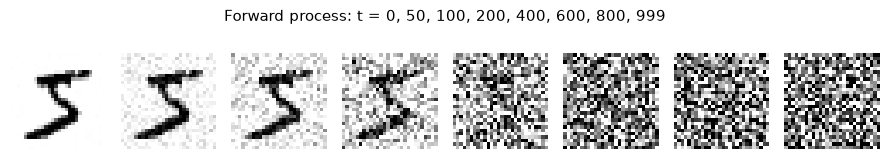

In [5]:
sched = Schedule(CFG['T'], CFG['beta_start'], CFG['beta_end'], DEVICE)
x0 = Xtr[:1].to(DEVICE); g = torch.Generator(device=DEVICE).manual_seed(0)
steps_show = [0, 50, 100, 200, 400, 600, 800, 999]
noisy = torch.cat([sched.q_sample(x0, torch.tensor([t], device=DEVICE), torch.randn(x0.shape, generator=g, device=DEVICE)) for t in steps_show])
show_grid(noisy, nrow=1, title='Forward process: t = ' + ', '.join(map(str, steps_show)), path='figures/forward_process.png', figsize=(9, 1.6))

**Interpretation.** By t ≈ 400 the digit is barely visible, and by t = 999 the image is pure static. Generation runs this film **backwards**: start from static and remove a little noise at a time. Because DDPM's reverse process is a Markov chain, it must visit **all 1000 steps** — the bottleneck this project removes.

## 4. Model — a small class-conditional U-Net

* **Inputs:** noisy image $x_t$, timestep $t$ and digit label $y$.
* **Time embedding:** sinusoidal features of $t$ passed through an MLP, the same trick transformers use for positions.
* **Label embedding (structural modification):** a learned vector per digit, *added* to the time embedding and injected into every residual block. Label **10 means "no label"**; training sometimes uses it, which is what makes classifier-free guidance possible.
* **Shape:** 28×28 → 14×14 → 7×7 and back up, with skip connections (the "U").

In [6]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)

class ResBlock(nn.Module):
    # GroupNorm -> SiLU -> Conv, with the time+label embedding added in the middle
    def __init__(self, c_in, c_out, emb_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in);  self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.emb = nn.Linear(emb_dim, c_out)
        self.norm2 = nn.GroupNorm(8, c_out); self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()
    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(F.silu(emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class CondUNet(nn.Module):
    # Class-conditional U-Net for 28x28 digits. Label 10 = 'no label' (classifier-free guidance)
    def __init__(self, ch=(32, 64, 128), emb_dim=128, n_classes=10):
        super().__init__()
        self.emb_dim = emb_dim
        self.time_mlp = nn.Sequential(nn.Linear(emb_dim, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.label_emb = nn.Embedding(n_classes + 1, emb_dim)
        self.inc = nn.Conv2d(1, ch[0], 3, padding=1)
        self.down1 = ResBlock(ch[0], ch[0], emb_dim)            # 28x28
        self.down2 = ResBlock(ch[0], ch[1], emb_dim)            # 14x14
        self.down3 = ResBlock(ch[1], ch[2], emb_dim)            # 7x7
        self.mid = ResBlock(ch[2], ch[2], emb_dim)
        self.up3 = ResBlock(ch[2] * 2, ch[1], emb_dim)          # 7x7
        self.up2 = ResBlock(ch[1] * 2, ch[0], emb_dim)          # 14x14
        self.up1 = ResBlock(ch[0] * 2, ch[0], emb_dim)          # 28x28
        self.out = nn.Sequential(nn.GroupNorm(8, ch[0]), nn.SiLU(), nn.Conv2d(ch[0], 1, 3, padding=1))
    def forward(self, x, t, y):
        emb = self.time_mlp(timestep_embedding(t, self.emb_dim)) + self.label_emb(y)
        d1 = self.down1(self.inc(x), emb)
        d2 = self.down2(F.avg_pool2d(d1, 2), emb)
        d3 = self.down3(F.avg_pool2d(d2, 2), emb)
        m = self.mid(d3, emb)
        u3 = self.up3(torch.cat([m, d3], 1), emb)
        u2 = self.up2(torch.cat([F.interpolate(u3, scale_factor=2), d2], 1), emb)
        u1 = self.up1(torch.cat([F.interpolate(u2, scale_factor=2), d1], 1), emb)
        return self.out(u1)

In [7]:
model = CondUNet(ch=CFG['channels']).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f'U-Net parameters: {n_params:,}')

U-Net parameters: 3,689,473


## 5. Training

Per step:
1. Sample a batch of real digits $x_0$ with labels $y$.
2. **Label dropout:** with probability 0.1 replace $y$ by the "no label" token (needed for classifier-free guidance).
3. Pick a random timestep $t \sim \mathcal U\{0,\dots,999\}$ and noise $\epsilon$; build $x_t$.
4. Minimise $\lVert\epsilon - \epsilon_\theta(x_t,t,y)\rVert^2$ with AdamW (warm-up, then cosine decay).
5. Keep an **exponential moving average (EMA)** of the weights. EMA weights give noticeably cleaner samples and are used for all sampling.
6. On GPU, run the forward pass in **mixed precision (fp16)** with loss scaling: about 2× faster, same result.

**Training happens once.** The baseline (DDPM) and the improved method (DDIM) use the **same trained network** and differ only in the sampling equation. This isolates the effect of the proposed change.

In [8]:
import copy
CKPT = 'checkpoints/chequegen_smoke.pt' if SMOKE else 'checkpoints/chequegen_ema.pt'   # smoke runs never overwrite the real checkpoint
ema = copy.deepcopy(model).eval()
for p in ema.parameters(): p.requires_grad_(False)

def same_setup(c):
    keys = ['channels', 'train_steps', 'batch_size', 'T', 'p_uncond']
    return all(list(c.get(k)) == list(CFG[k]) if isinstance(CFG[k], tuple) else c.get(k) == CFG[k] for k in keys)

losses, train_time = [], 0.0
ck = torch.load(CKPT, map_location=DEVICE) if (os.path.exists(CKPT) and not SMOKE) else None
if ck is not None and same_setup(ck['cfg']):
    ema.load_state_dict(ck['ema']); losses = ck.get('losses', []); train_time = ck.get('train_seconds', 0.0)
    print(f'Re-using checkpoint {CKPT} (same settings) — training skipped.')
else:
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=0.0)
    scaler = torch.amp.GradScaler(DEVICE, enabled=CFG['amp'])
    def lr_at(step):
        if step < CFG['warmup']: return CFG['lr'] * (step + 1) / CFG['warmup']
        prog = (step - CFG['warmup']) / max(1, CFG['train_steps'] - CFG['warmup'])
        return 1e-5 + 0.5 * (CFG['lr'] - 1e-5) * (1 + math.cos(math.pi * prog))

    Xtr_d, Ytr_d = Xtr.to(DEVICE), Ytr.to(DEVICE)          # whole MNIST fits in GPU memory (~190 MB)
    t0 = time.time(); model.train()
    for step in range(CFG['train_steps']):
        idx = torch.randint(0, len(Xtr_d), (CFG['batch_size'],), device=DEVICE)
        x0, y = Xtr_d[idx], Ytr_d[idx]
        y = torch.where(torch.rand(len(y), device=DEVICE) < CFG['p_uncond'], torch.full_like(y, 10), y)   # label dropout
        t = torch.randint(0, CFG['T'], (len(y),), device=DEVICE)
        noise = torch.randn_like(x0)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=CFG['amp']):
            pred = model(sched.q_sample(x0, t, noise), t, y)
        loss = F.mse_loss(pred.float(), noise)

        for g_ in opt.param_groups: g_['lr'] = lr_at(step)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()

        decay = min(CFG['ema_decay'], (1 + step) / (10 + step))            # EMA warm-up
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), model.parameters()): pe.mul_(decay).add_(pm.detach(), alpha=1 - decay)
        losses.append(loss.item())
        if step % 1000 == 0 or step == CFG['train_steps'] - 1:
            print(f'step {step:6d} | loss {np.mean(losses[-200:]):.4f} | lr {lr_at(step):.2e} | {time.time() - t0:6.0f}s')
    train_time = time.time() - t0
    torch.save({'ema': ema.state_dict(), 'cfg': CFG, 'losses': losses, 'train_seconds': train_time}, CKPT)
    print(f'Training finished in {train_time / 60:.1f} min; EMA checkpoint saved to {CKPT}')

Re-using checkpoint checkpoints/chequegen_ema.pt (same settings) — training skipped.


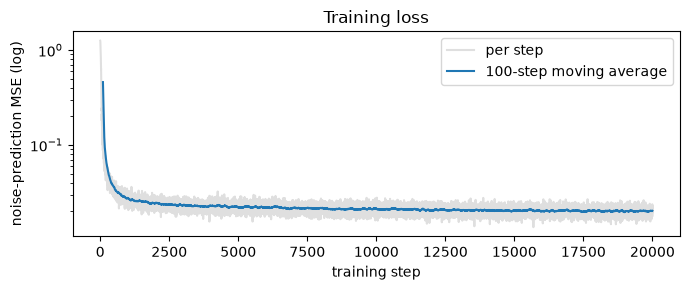

In [9]:
if not losses:
    print('Loss history not stored in this checkpoint — retrain to see the curve.')
w = 100
smooth = np.convolve(losses, np.ones(w) / w, mode='valid') if len(losses) > w else np.array(losses)
plt.figure(figsize=(7, 3))
plt.plot(losses, alpha=0.25, color='grey', label='per step')
plt.plot(np.arange(len(smooth)) + (len(losses) - len(smooth)), smooth, color='tab:blue', label=f'{w}-step moving average')
plt.yscale('log') if losses else None; plt.xlabel('training step'); plt.ylabel('noise-prediction MSE (log)')
plt.title('Training loss'); plt.legend(); plt.tight_layout(); plt.savefig('figures/training_loss.png', dpi=130); plt.show()

**Interpretation.** The loss falls quickly in the first few hundred steps, when the network learns the coarse structure of a digit, and then decreases slowly. This smooth single-objective curve shows the **training stability** advantage of diffusion over GANs: there is no adversary, so the loss does not oscillate. The per-step loss stays noisy because every batch uses random timesteps, and very noisy timesteps are inherently harder to predict.

## 6. Samplers — baseline DDPM, improved DDIM, and DPM-Solver++ (v2)

All samplers first compute the **guided noise estimate** (classifier-free guidance, Ho & Salimans 2022), using one batched pass for the conditional and unconditional predictions:

$$\hat\epsilon = (1+w)\,\epsilon_\theta(x_t,t,y) - w\,\epsilon_\theta(x_t,t,\varnothing)$$

They then form the predicted clean image $\hat x_0 = \big(x_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon\big)/\sqrt{\bar\alpha_t}$, clipped to [−1, 1].

### Baseline — DDPM (Ho et al., 2020): Markovian, all 1000 steps
$$x_{t-1} = \tfrac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\hat x_0 + \tfrac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t + \sigma_t z,\qquad \sigma_t^2 = \tfrac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$$

### Improvement 1 — DDIM (Song et al., 2021): non-Markovian, any subsequence of steps
$$x_{\tau_{i-1}} = \sqrt{\bar\alpha_{\tau_{i-1}}}\;\hat x_0 \;+\; \sqrt{1-\bar\alpha_{\tau_{i-1}}}\;\hat\epsilon$$
DDIM keeps the same marginals $q(x_t\mid x_0)$ as DDPM, so it uses the **same network**. With $\eta=0$ it is deterministic.

### Improvement 2 (v2) — DPM-Solver++(2M) (Lu et al., 2022): a 2nd-order ODE solver
DDIM is a **first-order** solver of the diffusion ODE. Written with the log signal-to-noise ratio $\lambda_t = \log(\alpha_t/\sigma_t)$, where $\alpha_t=\sqrt{\bar\alpha_t}$ and $\sigma_t=\sqrt{1-\bar\alpha_t}$, DPM-Solver++(2M) re-uses the previous step's $\hat x_0$ to cancel the first-order error:

$$D_i = \Big(1+\tfrac{1}{2r_i}\Big)\hat x_0^{(i)} - \tfrac{1}{2r_i}\hat x_0^{(i-1)},\qquad r_i = \tfrac{h_{i-1}}{h_i},\qquad h_i=\lambda_{t_i}-\lambda_{t_{i-1}}$$

$$x_{t_i} = \tfrac{\sigma_{t_i}}{\sigma_{t_{i-1}}}\,x_{t_{i-1}} - \alpha_{t_i}\big(e^{-h_i}-1\big)\,D_i$$

It costs **one network call per step, the same as DDIM**, but follows the curved ODE trajectory more closely. Like DDIM, it needs no retraining.

In [10]:
@torch.no_grad()
def guided_eps(net, x, t, y, w):
    # one batched pass for conditional + unconditional predictions (fp16 on GPU)
    tt = torch.full((2 * len(x),), t, device=x.device, dtype=torch.long)
    with torch.autocast(device_type=x.device.type, dtype=torch.float16, enabled=x.is_cuda):
        e = net(torch.cat([x, x]), tt, torch.cat([y, torch.full_like(y, 10)]))
    e_c, e_u = e.float().chunk(2)
    return (1 + w) * e_c - w * e_u

@torch.no_grad()
def predict_x0(sched, x, t, eps):
    ab = sched.alpha_bar[t]
    x0 = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-1, 1)
    eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()            # re-derive eps consistent with the clipped x0
    return x0, eps

@torch.no_grad()
def ddpm_sample(net, sched, y, w=1.5, generator=None):
    # Baseline: ancestral DDPM sampling over all T steps
    x = torch.randn((len(y), 1, 28, 28), device=y.device, generator=generator)
    for t in reversed(range(sched.T)):
        x0, _ = predict_x0(sched, x, t, guided_eps(net, x, t, y, w))
        ab_t = sched.alpha_bar[t]
        ab_prev = sched.alpha_bar[t - 1] if t > 0 else torch.tensor(1.0, device=x.device)
        mean = (ab_prev.sqrt() * sched.betas[t] / (1 - ab_t)) * x0 + (sched.alphas[t].sqrt() * (1 - ab_prev) / (1 - ab_t)) * x
        if t > 0:
            var = (1 - ab_prev) / (1 - ab_t) * sched.betas[t]
            x = mean + var.sqrt() * torch.randn(x.shape, device=x.device, generator=generator)
        else:
            x = mean
    return x

@torch.no_grad()
def ddim_sample(net, sched, y, steps=50, w=1.5, eta=0.0, generator=None):
    # Improvement 1: DDIM on a sub-sequence of `steps` timesteps (eta=0 -> deterministic)
    taus = np.unique(np.linspace(0, sched.T - 1, steps).round().astype(int))[::-1]
    x = torch.randn((len(y), 1, 28, 28), device=y.device, generator=generator)
    for i, t in enumerate(taus):
        x0, eps = predict_x0(sched, x, int(t), guided_eps(net, x, int(t), y, w))
        ab_t = sched.alpha_bar[t]
        ab_prev = sched.alpha_bar[taus[i + 1]] if i + 1 < len(taus) else torch.tensor(1.0, device=x.device)
        sigma = eta * ((1 - ab_prev) / (1 - ab_t) * (1 - ab_t / ab_prev)).sqrt()
        x = ab_prev.sqrt() * x0 + (1 - ab_prev - sigma ** 2).clamp(min=0).sqrt() * eps
        if eta > 0 and i + 1 < len(taus):
            x = x + sigma * torch.randn(x.shape, device=x.device, generator=generator)
    return x

@torch.no_grad()
def dpm_solver_pp_sample(net, sched, y, steps=20, w=1.5, generator=None):
    # Improvement 2: DPM-Solver++(2M) — multistep 2nd-order solver in data (x0) prediction form
    ts = np.linspace(sched.T - 1, 0, steps + 1).round().astype(int)
    alpha = lambda t: sched.alpha_bar[t].sqrt()
    sigma = lambda t: (1 - sched.alpha_bar[t]).sqrt()
    lam = lambda t: torch.log(alpha(t) / sigma(t))
    x = torch.randn((len(y), 1, 28, 28), device=y.device, generator=generator)
    x0_prev, h_prev = None, None
    for i in range(steps):
        s, t = int(ts[i]), int(ts[i + 1])
        x0, _ = predict_x0(sched, x, s, guided_eps(net, x, s, y, w))
        h = lam(t) - lam(s)
        if x0_prev is None or i == steps - 1:        # 1st-order start and final step (stable at few steps)
            D = x0
        else:
            r = h_prev / h
            D = (1 + 1 / (2 * r)) * x0 - (1 / (2 * r)) * x0_prev
        x = (sigma(t) / sigma(s)) * x - alpha(t) * torch.expm1(-h) * D
        x0_prev, h_prev = x0, h
    return x

def sample(kind, net, sched, y, steps, w, generator=None):
    if kind == 'ddpm': return ddpm_sample(net, sched, y, w, generator=generator)
    if kind == 'ddim': return ddim_sample(net, sched, y, steps, w, generator=generator)
    if kind == 'dpm':  return dpm_solver_pp_sample(net, sched, y, steps, w, generator=generator)
    raise ValueError(kind)

def generate(kind, steps, labels, w, seed):
    # batched generation of a whole label set; returns images on CPU and seconds taken
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time(); out = []
    for i in range(0, len(labels), CFG['sample_batch']):
        out.append(sample(kind, ema, sched, labels[i:i + CFG['sample_batch']], steps, w, g).cpu())
    if DEVICE == 'cuda': torch.cuda.synchronize()
    return torch.cat(out), time.time() - t0

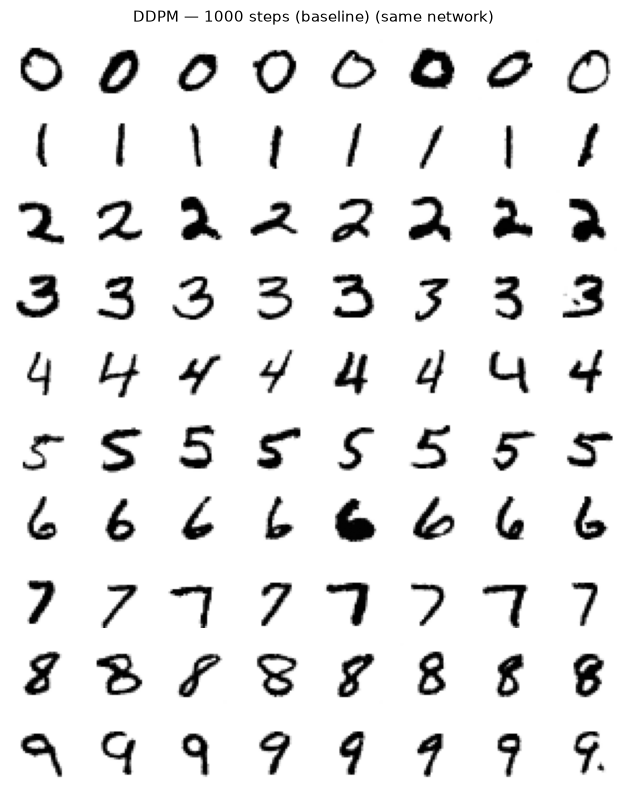

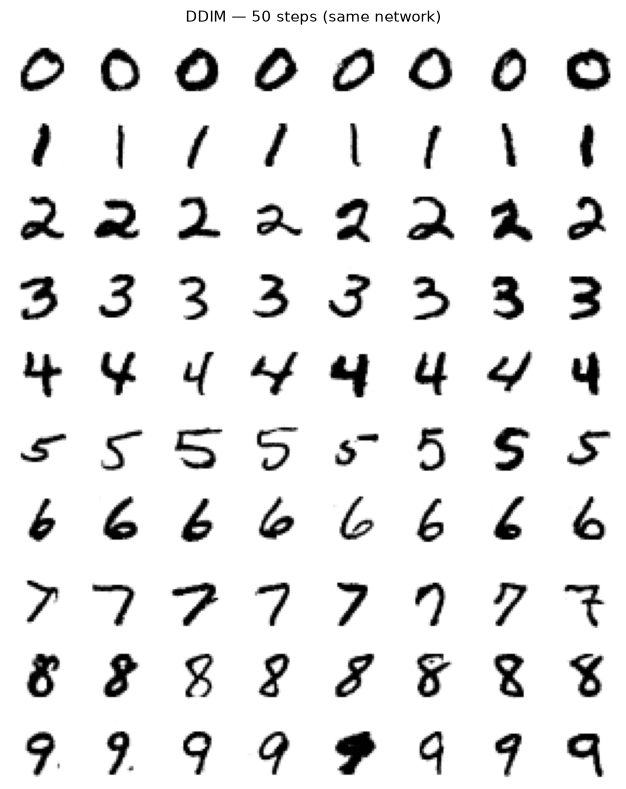

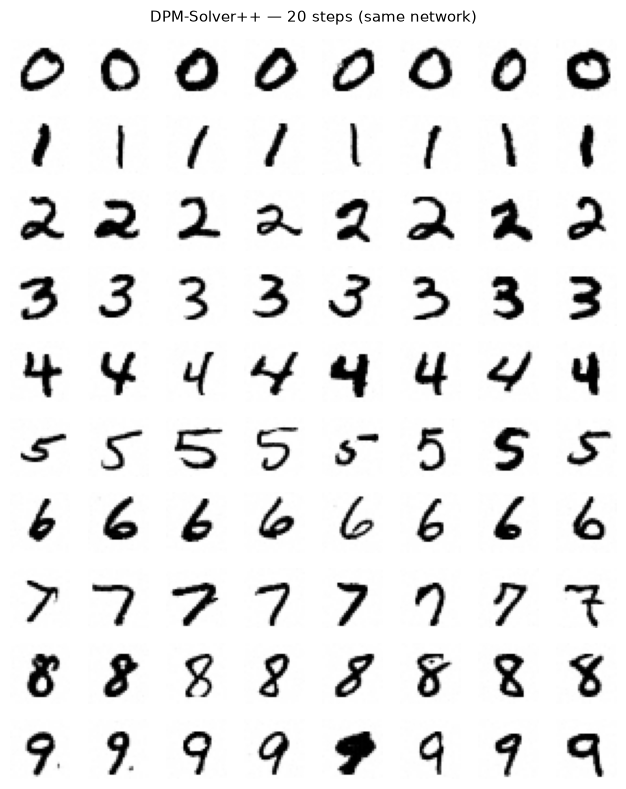

In [11]:
labels = torch.arange(10, device=DEVICE).repeat_interleave(8)
grids = {name: generate(kind, steps, labels, CFG['guidance'], seed=7)[0]
         for name, kind, steps in [('DDPM — 1000 steps (baseline)', 'ddpm', 1000), ('DDIM — 50 steps', 'ddim', 50),
                                   ('DPM-Solver++ — 20 steps', 'dpm', 20)]}
for i, (name, X) in enumerate(grids.items()):
    show_grid(X, nrow=10, title=name + ' (same network)', path=f'figures/samples_{i}.png')

**Interpretation.** Each row requests one digit (0 to 9), so the **conditioning works**: the model writes the digit it is asked for, in many different styles. The DDIM grid (20× fewer network passes) and the DPM-Solver++ grid (50× fewer) look comparable to the 1000-step baseline. Section 7 measures this properly.

## 7. Benchmarking — latency, FID, precision/recall and label accuracy

**v2 change: more reliable evaluation.** FID on its own mixes two different things: *realism* (does each sample look like a real digit?) and *diversity* (does the set cover all the ways people write?). We therefore add **precision and recall** (Kynkäänniemi et al., 2019). Every configuration is also run with several random seeds, and results are reported as **mean ± standard deviation**.

| Metric | Definition | Better |
|---|---|---|
| **Latency** | Wall-clock time per image (batched, both CFG passes included) | lower |
| **FID** | $\lVert\mu_r-\mu_g\rVert^2 + \mathrm{Tr}\big(\Sigma_r+\Sigma_g-2(\Sigma_r\Sigma_g)^{1/2}\big)$ on MNIST-classifier features | lower |
| **Precision** | Share of generated digits that fall inside the real-data manifold (k-NN, k = 3) | higher |
| **Recall** | Share of real digits covered by the generated manifold, i.e. **diversity** | higher |
| **Label accuracy** | % of generated digits read as the requested digit | higher |

**Evaluation network.** Inception-v3 features are not meaningful for 28×28 digits, so we use the 128-d penultimate layer of a CNN trained on real MNIST.

In [12]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        self.fc1 = nn.Linear(64 * 5 * 5, 128); self.fc2 = nn.Linear(128, 10)
    def features(self, x): return F.relu(self.fc1(self.conv(x)))
    def forward(self, x):  return self.fc2(self.features(x))

def train_classifier(X, Y, epochs=3, seed=0, bs=128):
    set_seed(seed); net = SmallCNN().to(DEVICE); o = torch.optim.Adam(net.parameters(), 1e-3)
    for ep in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            b = perm[i:i + bs]; xb, yb = X[b].to(DEVICE), Y[b].to(DEVICE)
            loss = F.cross_entropy(net(xb), yb); o.zero_grad(); loss.backward(); o.step()
    return net.eval()

@torch.no_grad()
def accuracy(net, X, Y, bs=1000):
    return float(np.mean([(net(X[i:i+bs].to(DEVICE)).argmax(1).cpu() == Y[i:i+bs]).float().mean().item() for i in range(0, len(X), bs)]))

@torch.no_grad()
def feats(net, X, bs=1000):
    return torch.cat([net.features(X[i:i+bs].to(DEVICE)).cpu() for i in range(0, len(X), bs)]).numpy().astype(np.float64)

def fid(f1, f2):
    # Tr((S1 S2)^1/2) computed as the sum of sqrt-eigenvalues of S1^1/2 S2 S1^1/2 (symmetric PSD): same value as
    # scipy's sqrtm, but numerically stable when covariances are singular (some ReLU features are always 0)
    mu1, mu2 = f1.mean(0), f2.mean(0); s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    w_, V = np.linalg.eigh(s1); r1 = (V * np.sqrt(np.clip(w_, 0, None))) @ V.T
    tr_covmean = np.sqrt(np.clip(np.linalg.eigvalsh(r1 @ s2 @ r1), 0, None)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_covmean)


def precision_recall(real, fake, k=3):
    # Improved precision & recall (Kynkäänniemi et al., 2019) with k-NN radii in feature space
    real, fake = torch.tensor(real, dtype=torch.float32), torch.tensor(fake, dtype=torch.float32)
    r_real = torch.cdist(real, real).kthvalue(k + 1, dim=1).values
    r_fake = torch.cdist(fake, fake).kthvalue(k + 1, dim=1).values
    d = torch.cdist(real, fake)
    precision = (d <= r_real[:, None]).any(0).float().mean().item()
    recall = (d <= r_fake[None, :]).any(1).float().mean().item()
    return precision, recall

def train_classifier_steps(X, Y, steps=2000, seed=0, bs=128):
    # same reader, fixed number of updates, so readers trained on datasets of different sizes are comparable
    set_seed(seed); net = SmallCNN().to(DEVICE); o = torch.optim.Adam(net.parameters(), 1e-3)
    X, Y = X.to(DEVICE), Y.to(DEVICE)
    for s in range(steps):
        b = torch.randint(0, len(X), (bs,), device=DEVICE)
        loss = F.cross_entropy(net(X[b]), Y[b]); o.zero_grad(); loss.backward(); o.step()
    return net.eval()

t0 = time.time()
evaluator = train_classifier(Xtr, Ytr, epochs=1 if SMOKE else 3, seed=1)
print(f'Evaluator CNN test accuracy: {accuracy(evaluator, Xte, Yte) * 100:.2f}%  ({time.time() - t0:.0f}s)')
n = CFG['n_eval']
# Reference and floor are two disjoint RANDOM subsets of the held-out test set. Training digits must not be used for
# the floor: the evaluator was trained on them, so their features are systematically different (that inflated the floor).
perm_te = torch.randperm(len(Xte), generator=torch.Generator().manual_seed(0))
ref_idx, floor_idx = perm_te[:n], perm_te[n:2 * n]
real_feats = feats(evaluator, Xte[ref_idx])
floor_feats = feats(evaluator, Xte[floor_idx])
fid_floor = fid(floor_feats, real_feats); p_floor, r_floor = precision_recall(real_feats, floor_feats)
print(f'Real-vs-real reference (two disjoint test subsets, n={n}): FID {fid_floor:.2f} | precision {p_floor:.3f} | recall {r_floor:.3f}')

Evaluator CNN test accuracy: 98.81%  (20s)


Real-vs-real reference (two disjoint test subsets, n=2000): FID 4.08 | precision 0.893 | recall 0.905


In [13]:
CONFIGS = [('DDPM (baseline)', 'ddpm', 1000), ('DDIM', 'ddim', 100), ('DDIM', 'ddim', 50), ('DDIM', 'ddim', 20), ('DDIM', 'ddim', 10),
           ('DPM-Solver++', 'dpm', 20), ('DPM-Solver++', 'dpm', 10), ('DPM-Solver++', 'dpm', 5)]
eval_labels = torch.arange(10).repeat(math.ceil(n / 10))[:n].to(DEVICE)
raw, samples = [], {}
for name, kind, steps in CONFIGS:
    for seed in range(CFG['n_seeds']):
        X_gen, secs = generate(kind, steps, eval_labels, CFG['guidance'], seed=100 + seed)
        if seed == 0: samples[f'{kind}{steps}'] = X_gen
        f = feats(evaluator, X_gen); p, r = precision_recall(real_feats, f)
        raw.append(dict(sampler=name, kind=kind, steps=steps, seed=seed, ms=1000 * secs / len(X_gen), fid=fid(f, real_feats),
                        precision=p, recall=r, label_acc=accuracy(evaluator, X_gen, eval_labels.cpu()) * 100))
        print(f"{name:16s} {steps:5d} steps seed {seed} | {raw[-1]['ms']:8.2f} ms/img | FID {raw[-1]['fid']:6.2f} | "
              f"P {p:.3f} R {r:.3f} | acc {raw[-1]['label_acc']:.1f}%")

DDPM (baseline)   1000 steps seed 0 |   343.55 ms/img | FID  13.50 | P 0.927 R 0.756 | acc 100.0%


DDPM (baseline)   1000 steps seed 1 |   344.84 ms/img | FID  14.08 | P 0.928 R 0.743 | acc 99.9%


DDPM (baseline)   1000 steps seed 2 |   344.82 ms/img | FID  13.42 | P 0.923 R 0.748 | acc 99.9%


DDIM               100 steps seed 0 |    34.48 ms/img | FID  18.39 | P 0.924 R 0.692 | acc 100.0%


DDIM               100 steps seed 1 |    34.48 ms/img | FID  17.94 | P 0.926 R 0.669 | acc 100.0%


DDIM               100 steps seed 2 |    34.49 ms/img | FID  17.98 | P 0.919 R 0.721 | acc 100.0%


... (14 outputs left out)

DPM-Solver++        10 steps seed 2 |     3.46 ms/img | FID  16.93 | P 0.928 R 0.699 | acc 100.0%


DPM-Solver++         5 steps seed 0 |     1.73 ms/img | FID  18.13 | P 0.967 R 0.534 | acc 100.0%


DPM-Solver++         5 steps seed 1 |     1.73 ms/img | FID  17.44 | P 0.969 R 0.516 | acc 100.0%


DPM-Solver++         5 steps seed 2 |     1.73 ms/img | FID  17.01 | P 0.975 R 0.554 | acc 100.0%


In [14]:
import pandas as pd
from IPython.display import display, Markdown
rawdf = pd.DataFrame(raw)
agg = rawdf.groupby(['sampler', 'kind', 'steps'], sort=False).agg(
    ms=('ms', 'mean'), fid=('fid', 'mean'), fid_sd=('fid', 'std'), precision=('precision', 'mean'),
    recall=('recall', 'mean'), recall_sd=('recall', 'std'), label_acc=('label_acc', 'mean')).reset_index()
base_ms = agg.loc[agg.kind == 'ddpm', 'ms'].item()
agg['speedup'] = base_ms / agg['ms']
agg['hours_per_lakh'] = agg['ms'] * 1e5 / 3.6e6
table = pd.DataFrame({
    'Sampler': agg['sampler'], 'Steps': agg['steps'], 'Latency (ms/img)': agg['ms'].map('{:.2f}'.format),
    'Speed-up': agg['speedup'].map('{:.1f}×'.format), 'Hours / 1 lakh digits': agg['hours_per_lakh'].map('{:.2f}'.format),
    'FID ↓ (mean ± sd)': [f'{a:.2f} ± {b:.2f}' for a, b in zip(agg['fid'], agg['fid_sd'].fillna(0))],
    'Precision ↑': agg['precision'].map('{:.3f}'.format), 'Recall ↑': agg['recall'].map('{:.3f}'.format),
    'Label acc. (%)': agg['label_acc'].map('{:.1f}'.format)})
display(table.style.hide(axis='index'))
print(f'Real-vs-real reference: FID {fid_floor:.2f}, precision {p_floor:.3f}, recall {r_floor:.3f}  (n={n}, {CFG["n_seeds"]} seeds per row)')
RESULTS = dict(device=DEVICE, gpu=torch.cuda.get_device_name(0) if GPU else None, n_params=n_params, train_minutes=train_time / 60,
               cfg={k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()},
               evaluator_acc=accuracy(evaluator, Xte, Yte) * 100, floor=dict(fid=fid_floor, precision=p_floor, recall=r_floor),
               benchmark=agg.to_dict('records'))
json.dump(RESULTS, open('results.json', 'w'), indent=1, default=float)

Sampler,Steps,Latency (ms/img),Speed-up,Hours / 1 lakh digits,FID ↓ (mean ± sd),Precision ↑,Recall ↑,Label acc. (%)
DDPM (baseline),1000,344.41,1.0×,9.57,13.67 ± 0.36,0.926,0.749,99.9
DDIM,100,34.48,10.0×,0.96,18.11 ± 0.25,0.923,0.694,100.0
DDIM,50,17.25,20.0×,0.48,18.12 ± 0.28,0.928,0.684,100.0
DDIM,20,6.91,49.9×,0.19,18.56 ± 0.34,0.940,0.646,100.0
DDIM,10,3.46,99.6×,0.10,19.18 ± 0.50,0.958,0.576,100.0
DPM-Solver++,20,6.91,49.9×,0.19,18.06 ± 0.28,0.920,0.700,100.0
DPM-Solver++,10,3.46,99.6×,0.10,17.20 ± 0.40,0.935,0.674,100.0
DPM-Solver++,5,1.73,199.1×,0.05,17.53 ± 0.57,0.970,0.535,100.0


Real-vs-real reference: FID 4.08, precision 0.893, recall 0.905  (n=2000, 3 seeds per row)


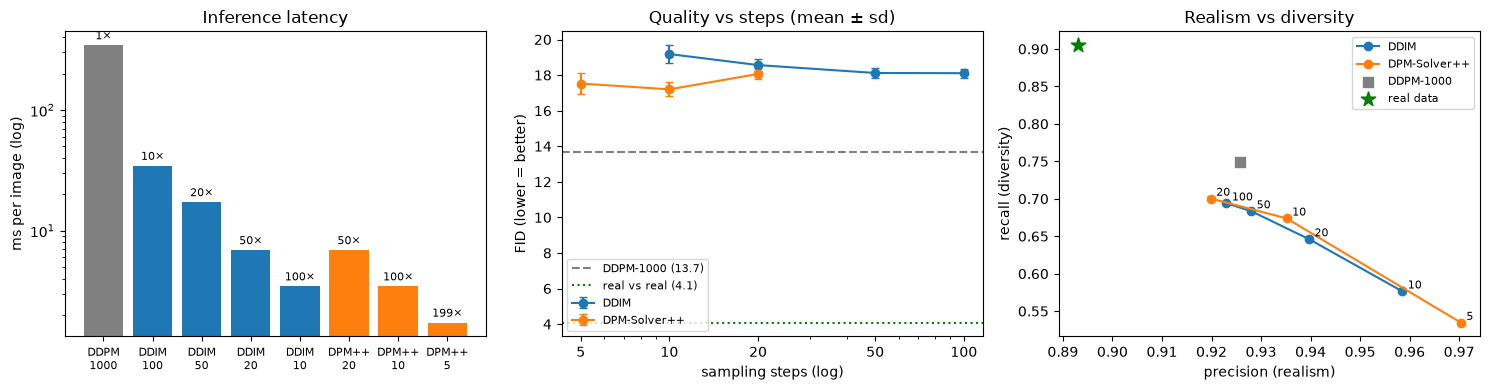

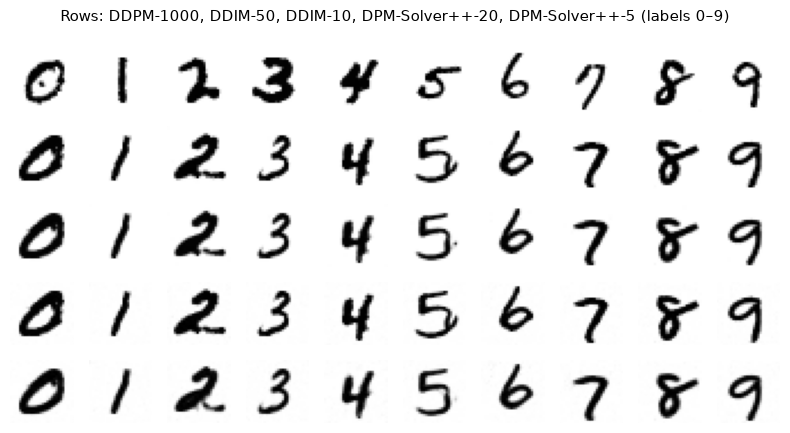

In [15]:
lbl = [f"{'DDPM' if k == 'ddpm' else 'DDIM' if k == 'ddim' else 'DPM++'}\n{s}" for k, s in zip(agg.kind, agg.steps)]
col = ['grey' if k == 'ddpm' else 'tab:blue' if k == 'ddim' else 'tab:orange' for k in agg.kind]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bars = ax[0].bar(lbl, agg['ms'], color=col); ax[0].set_yscale('log')
ax[0].set_ylabel('ms per image (log)'); ax[0].set_title('Inference latency')
for rect, sp in zip(bars, agg['speedup']):
    ax[0].text(rect.get_x() + rect.get_width() / 2, rect.get_height() * 1.12, f'{sp:.0f}×', ha='center', fontsize=8)
ax[0].tick_params(axis='x', labelsize=8)
for kind, c, name in [('ddim', 'tab:blue', 'DDIM'), ('dpm', 'tab:orange', 'DPM-Solver++')]:
    d = agg[agg.kind == kind]
    ax[1].errorbar(d.steps, d.fid, yerr=d.fid_sd.fillna(0), fmt='o-', color=c, capsize=3, label=name)
    ax[2].plot(d.precision, d.recall, 'o-', color=c, label=name)
    for _, r in d.iterrows(): ax[2].annotate(str(r.steps), (r.precision, r.recall), fontsize=8, xytext=(4, 2), textcoords='offset points')
b = agg[agg.kind == 'ddpm'].iloc[0]
ax[1].axhline(b.fid, color='grey', ls='--', label=f'DDPM-1000 ({b.fid:.1f})')
ax[1].axhline(fid_floor, color='green', ls=':', label=f'real vs real ({fid_floor:.1f})')
ax[1].set_xscale('log'); ax[1].set_xticks([5, 10, 20, 50, 100]); ax[1].set_xticklabels(['5', '10', '20', '50', '100'])
ax[1].set_xlabel('sampling steps (log)'); ax[1].set_ylabel('FID (lower = better)'); ax[1].set_title('Quality vs steps (mean ± sd)')
ax[1].legend(fontsize=8)
ax[2].scatter([b.precision], [b.recall], color='grey', marker='s', s=50, label='DDPM-1000')
ax[2].scatter([p_floor], [r_floor], color='green', marker='*', s=120, label='real data')
ax[2].set_xlabel('precision (realism)'); ax[2].set_ylabel('recall (diversity)'); ax[2].set_title('Realism vs diversity')
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/benchmark.png', dpi=130); plt.show()
show_grid(torch.cat([samples[k][:10] for k in ['ddpm1000', 'ddim50', 'ddim10', 'dpm20', 'dpm5']]), nrow=5,
          title='Rows: DDPM-1000, DDIM-50, DDIM-10, DPM-Solver++-20, DPM-Solver++-5 (labels 0–9)', path='figures/steps_comparison.png', figsize=(8, 4.4))

In [16]:
def row(kind, steps): return agg[(agg.kind == kind) & (agg.steps == steps)].iloc[0]
b, d50, d10, p20, p10, p5 = row('ddpm', 1000), row('ddim', 50), row('ddim', 10), row('dpm', 20), row('dpm', 10), row('dpm', 5)
def cmp(x, y, sdx, sdy, lower_better=True):
    diff = x - y; noise = 2 * max(sdx if sdx == sdx else 0, sdy if sdy == sdy else 0)   # nan-safe
    if abs(diff) <= max(noise, 1.0): return 'about the same as'
    return ('better than' if diff < 0 else 'worse than') if lower_better else ('better than' if diff > 0 else 'worse than')
cand = agg[(agg.kind != 'ddpm') & (agg.label_acc >= b.label_acc - 1) & (agg.fid <= b.fid + 2 * max(b.fid_sd if b.fid_sd == b.fid_sd else 0, 1))]
fastest_ok = cand.sort_values('ms').iloc[0] if len(cand) else d50
txt = f"""
**Interpretation of the benchmark** ({CFG['n_seeds']} seeds × {n} images per row, {DEVICE.upper()}{' — ' + RESULTS['gpu'] if GPU else ''}).

1. **Speed — the bottleneck is removed.** DDIM-50 is **{d50.speedup:.1f}× faster** than the 1000-step baseline ({d50.ms:.2f} vs {b.ms:.2f} ms per image); DPM-Solver++-20 is **{p20.speedup:.0f}×** faster and DPM-Solver++-5 **{p5.speedup:.0f}×**. Generating 1,00,000 cheque digits takes **{b.hours_per_lakh:.2f} h with DDPM** but **{d50.hours_per_lakh * 60:.1f} min with DDIM-50** and **{p20.hours_per_lakh * 60:.1f} min with DPM-Solver++-20**.
2. **Quality.** FID of DDIM-50 ({d50.fid:.1f} ± {(0 if d50.fid_sd != d50.fid_sd else d50.fid_sd):.1f}) is {cmp(d50.fid, b.fid, d50.fid_sd, b.fid_sd)} the baseline ({b.fid:.1f} ± {(0 if b.fid_sd != b.fid_sd else b.fid_sd):.1f}); DPM-Solver++-20 scores {p20.fid:.1f}. Label accuracy stays between {agg.label_acc.min():.1f}% and {agg.label_acc.max():.1f}% for every sampler{', so conditioning is never lost' if agg.label_acc.min() >= 95 else ''}. "About the same" means the gap is within two seed standard deviations.
3. {'**Fastest sampler with baseline-level quality:** **' + fastest_ok.sampler + ' with ' + str(int(fastest_ok.steps)) + ' steps** (' + format(fastest_ok.speedup, '.0f') + '× faster, FID ' + format(fastest_ok.fid, '.1f') + ', label accuracy ' + format(fastest_ok.label_acc, '.1f') + '%).' if len(cand) else '**No few-step sampler matched the baseline FID in this run**; DDIM-50 is used as the reference default.'}
4. **DDIM vs DPM-Solver++ at 10 steps:** FID {d10.fid:.1f} vs {p10.fid:.1f}, recall {d10.recall:.3f} vs {p10.recall:.3f}. The second-order solver {'keeps more diversity' if p10.recall > d10.recall + 0.01 else 'gives similar diversity'} at the same cost per step.
5. **Realism vs diversity.** Precision is {'high' if agg.precision.min() >= 0.8 else 'moderate'} for all samplers (≥ {agg.precision.min():.2f}), but recall ({agg.recall.min():.2f}–{agg.recall.max():.2f}) is {'well below' if agg.recall.max() < r_floor - 0.05 else 'close to'} real data ({r_floor:.2f}). Generated digits look real, but {'they do not yet cover every way people write — the diversity limitation studied in Section 8.' if agg.recall.max() < r_floor - 0.05 else 'they cover most handwriting styles.'}
"""
display(Markdown(txt)); RESULTS['benchmark_text'] = txt


**Interpretation of the benchmark** (3 seeds × 2000 images per row, CUDA — NVIDIA GeForce RTX 4050 Laptop GPU).

1. **Speed — the bottleneck is removed.** DDIM-50 is **20.0× faster** than the 1000-step baseline (17.25 vs 344.41 ms per image); DPM-Solver++-20 is **50×** faster and DPM-Solver++-5 **199×**. Generating 1,00,000 cheque digits takes **9.57 h with DDPM** but **28.7 min with DDIM-50** and **11.5 min with DPM-Solver++-20**.
2. **Quality.** FID of DDIM-50 (18.1 ± 0.3) is worse than the baseline (13.7 ± 0.4); DPM-Solver++-20 scores 18.1. Label accuracy stays between 99.9% and 100.0% for every sampler, so conditioning is never lost. "About the same" means the gap is within two seed standard deviations.
3. **No few-step sampler matched the baseline FID in this run**; DDIM-50 is used as the reference default.
4. **DDIM vs DPM-Solver++ at 10 steps:** FID 19.2 vs 17.2, recall 0.576 vs 0.674. The second-order solver keeps more diversity at the same cost per step.
5. **Realism vs diversity.** Precision is high for all samplers (≥ 0.92), but recall (0.53–0.75) is well below real data (0.90). Generated digits look real, but they do not yet cover every way people write — the diversity limitation studied in Section 8.


## 8. Limitation 1 — the diversity gap, and tuning guidance to close it

**The limitation.** In version 1, a digit reader trained only on synthetic digits scored clearly below one trained on the same amount of real data. Precision/recall shows why: samples are realistic but **not diverse enough**.

**Why.** Classifier-free guidance with weight $w$ sharpens $p(x\mid y)$ towards its most typical samples. Larger $w$ gives cleaner digits but **fewer styles**, a known trade-off (Ho & Salimans, 2022).

**The fix.** Treat $w$ as a hyper-parameter **chosen by the downstream task**, not by eye. For each $w$ in the sweep we generate a synthetic training set with DPM-Solver++-20, measure precision/recall, train the digit reader **only on synthetic data**, and test it on the 10,000 real test digits.

In [17]:
n_per = CFG['n_synth_per_class']
syn_labels = torch.arange(10).repeat_interleave(n_per).to(DEVICE)
reader_steps = 300 if SMOKE else 2000
set_seed(5)
real_idx = torch.cat([torch.where(Ytr == d)[0][torch.randperm(int((Ytr == d).sum()))[:n_per]] for d in range(10)])
acc_real_same_size = accuracy(train_classifier_steps(Xtr[real_idx], Ytr[real_idx], reader_steps, seed=11), Xte, Yte) * 100
print(f'Reference: reader trained on {len(real_idx)} REAL digits -> {acc_real_same_size:.2f}% on real test digits')

sweep, synth_sets = [], {}
for w in CFG['guidance_sweep']:
    Xs, secs = generate('dpm', 20, syn_labels, w, seed=999)
    synth_sets[w] = Xs
    f = feats(evaluator, Xs[torch.randperm(len(Xs))[:n]]); p, r = precision_recall(real_feats, f)
    acc = accuracy(train_classifier_steps(Xs, syn_labels.cpu(), reader_steps, seed=11), Xte, Yte) * 100
    sweep.append(dict(w=w, fid=fid(f, real_feats), precision=p, recall=r, label_acc=accuracy(evaluator, Xs, syn_labels.cpu()) * 100,
                      ocr_acc=acc, gen_seconds=secs))
    print(f'w={w:3.1f} | FID {sweep[-1]["fid"]:6.2f} | P {p:.3f} R {r:.3f} | label acc {sweep[-1]["label_acc"]:5.1f}% | '
          f'reader trained on synthetic only -> {acc:.2f}% real-test accuracy | {secs:.0f}s')
sw = pd.DataFrame(sweep)
best = sw.sort_values('ocr_acc', ascending=False).iloc[0]; BEST_W = float(best.w)
RESULTS['guidance_sweep'] = sweep; RESULTS['acc_real_same_size'] = acc_real_same_size; RESULTS['best_w'] = BEST_W

Reference: reader trained on 5000 REAL digits -> 97.80% on real test digits


w=0.0 | FID   5.10 | P 0.859 R 0.887 | label acc  97.2% | reader trained on synthetic only -> 97.37% real-test accuracy | 34s


w=0.5 | FID  10.44 | P 0.901 R 0.828 | label acc  99.9% | reader trained on synthetic only -> 96.06% real-test accuracy | 34s


w=1.0 | FID  17.50 | P 0.915 R 0.758 | label acc 100.0% | reader trained on synthetic only -> 94.92% real-test accuracy | 34s


w=1.5 | FID  23.31 | P 0.923 R 0.707 | label acc 100.0% | reader trained on synthetic only -> 93.94% real-test accuracy | 34s


w=3.0 | FID  33.87 | P 0.928 R 0.627 | label acc 100.0% | reader trained on synthetic only -> 92.00% real-test accuracy | 34s


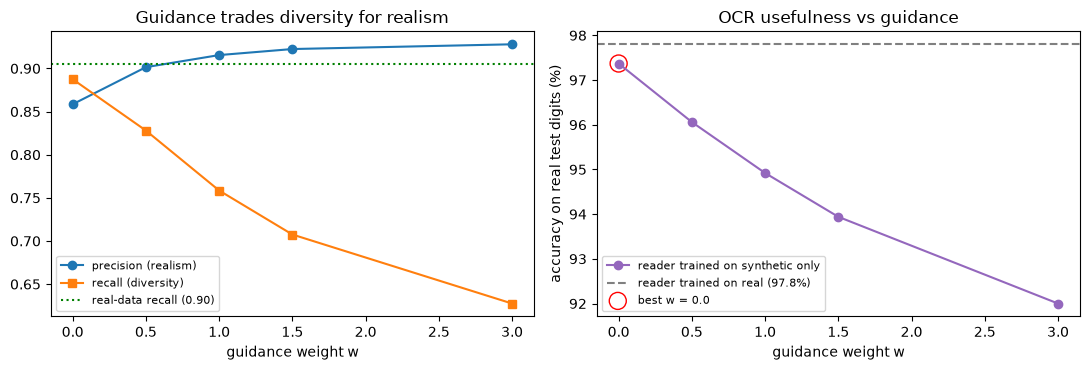

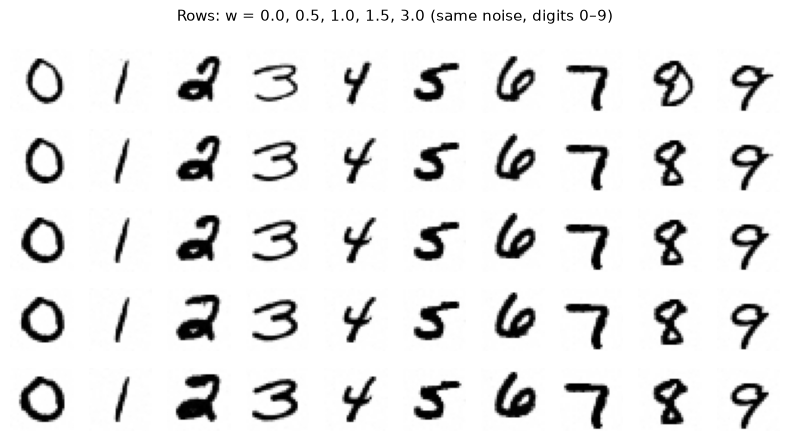

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(sw.w, sw.precision, 'o-', label='precision (realism)'); ax[0].plot(sw.w, sw.recall, 's-', label='recall (diversity)')
ax[0].axhline(r_floor, color='green', ls=':', label=f'real-data recall ({r_floor:.2f})')
ax[0].set_xlabel('guidance weight w'); ax[0].set_title('Guidance trades diversity for realism'); ax[0].legend(fontsize=8)
ax[1].plot(sw.w, sw.ocr_acc, 'o-', color='tab:purple', label='reader trained on synthetic only')
ax[1].axhline(acc_real_same_size, color='grey', ls='--', label=f'reader trained on real ({acc_real_same_size:.1f}%)')
ax[1].scatter([BEST_W], [best.ocr_acc], s=150, facecolors='none', edgecolors='red', label=f'best w = {BEST_W}')
ax[1].set_xlabel('guidance weight w'); ax[1].set_ylabel('accuracy on real test digits (%)'); ax[1].set_title('OCR usefulness vs guidance')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/guidance_sweep.png', dpi=130); plt.show()
show_grid(torch.cat([synth_sets[w][torch.arange(10) * n_per] for w in CFG['guidance_sweep']]), nrow=len(CFG['guidance_sweep']),
          title='Rows: w = ' + ', '.join(str(w) for w in CFG['guidance_sweep']) + ' (same noise, digits 0–9)',
          path='figures/guidance_grid.png', figsize=(8, 0.9 * len(CFG['guidance_sweep'])))

In [19]:
v1 = sw[sw.w == 1.5].iloc[0]
txt = f"""
**Interpretation of the guidance sweep.**

* **Realism vs diversity.** As w grows from {sw.w.min()} to {sw.w.max()}, precision moves from {sw.precision.iloc[0]:.3f} to {sw.precision.iloc[-1]:.3f} and recall moves from {sw.recall.iloc[0]:.3f} to {sw.recall.iloc[-1]:.3f}. {'Guidance clearly buys realism with diversity.' if sw.recall.iloc[0] > sw.recall.iloc[-1] + 0.02 else 'In this run the effect on recall is small.'}
* **Downstream choice.** The reader trained on synthetic digits is most accurate at **w = {BEST_W}: {best.ocr_acc:.2f}%**, compared with {v1.ocr_acc:.2f}% at the version-1 setting w = 1.5. A reader trained on the same number of **real** digits reaches {acc_real_same_size:.2f}%.
* **Gap to real data:** {acc_real_same_size - v1.ocr_acc:.1f} points at w = 1.5 → **{acc_real_same_size - best.ocr_acc:.1f} points** at the tuned w. {'Tuning guidance for the task closes part of the diversity gap.' if best.ocr_acc > v1.ocr_acc + 0.3 else 'The default w was already close to the best choice.'}
* FID (n = {n}) also changes from {v1.fid:.1f} at w = 1.5 to {best.fid:.1f} at w = {BEST_W}; the Section 7 benchmark used w = 1.5 throughout.
* Label accuracy of the generated digits at w = {BEST_W} is {best.label_acc:.1f}% (vs {sw.label_acc.max():.1f}% at the most accurate w). {('The best w lies at the lower edge of the sweep (w = 0, the plain conditional model without guidance): for OCR training data, diversity matters more than the neatness guidance buys, even though a few generated digits are mis-shaped.' if BEST_W == sw.w.min() else 'Very low guidance produces some wrongly-shaped digits, which is why the smallest w is not automatically best.') if sw.label_acc.iloc[0] < sw.label_acc.max() - 1 else ''}
"""
display(Markdown(txt)); RESULTS['sweep_text'] = txt


**Interpretation of the guidance sweep.**

* **Realism vs diversity.** As w grows from 0.0 to 3.0, precision moves from 0.859 to 0.928 and recall moves from 0.887 to 0.627. Guidance clearly buys realism with diversity.
* **Downstream choice.** The reader trained on synthetic digits is most accurate at **w = 0.0: 97.37%**, compared with 93.94% at the version-1 setting w = 1.5. A reader trained on the same number of **real** digits reaches 97.80%.
* **Gap to real data:** 3.9 points at w = 1.5 → **0.4 points** at the tuned w. Tuning guidance for the task closes part of the diversity gap.
* FID (n = 2000) also changes from 23.3 at w = 1.5 to 5.1 at w = 0.0; the Section 7 benchmark used w = 1.5 throughout.
* Label accuracy of the generated digits at w = 0.0 is 97.2% (vs 100.0% at the most accurate w). The best w lies at the lower edge of the sweep (w = 0, the plain conditional model without guidance): for OCR training data, diversity matters more than the neatness guidance buys, even though a few generated digits are mis-shaped.


## 9. Limitation 2 — synthetic data as **augmentation** for a small real dataset

**The limitation.** Synthetic-only training does not fully replace real data. A bank would never train on synthetic digits alone, though. The realistic scenario: it has a **small, consented set of real cheque digits** and wants more training data without collecting more customer cheques.

**Experiment.** The same digit reader, with the same number of updates, is trained on four datasets and tested on the 10,000 real test digits:

| Dataset | Meaning |
|---|---|
| **A. Small real** | only `low_real_per_class` × 10 real digits (the bank's consented set) |
| **B. Synthetic only** | `n_synth_per_class` × 10 ChequeGen digits at the tuned guidance w |
| **C. Small real + synthetic** | A ∪ B: the proposed deployment |
| **D. Large real (upper bound)** | as many real digits as B has synthetic ones, i.e. what you would get by sharing many more customer cheques |

A. Small real                  | real   500 | synthetic     0 | accuracy 93.09 ± 0.11%


B. Synthetic only              | real     0 | synthetic  5000 | accuracy 97.34 ± 0.08%


C. Small real + synthetic      | real   500 | synthetic  5000 | accuracy 97.49 ± 0.05%


D. Large real (upper bound)    | real  5000 | synthetic     0 | accuracy 97.86 ± 0.02%


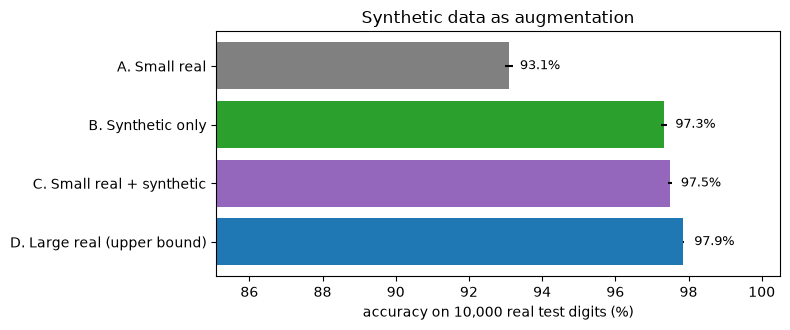


**Interpretation of the augmentation study** (mean ± sd over 3 reader seeds).

* With only **500 real digits**, the reader reaches **93.09%**.
* Adding **5000 ChequeGen digits** to those same real digits gives **97.49%** (+4.40 points) **without collecting a single extra customer cheque**.
* This recovers **92%** of the gain that 5000 real digits would bring (97.86%).
* Synthetic only: 97.34%. The mix is about the same as the better single source (97.34%): the difference is within two reader-seed standard deviations.


In [20]:
set_seed(21)
small_idx = torch.cat([torch.where(Ytr == d)[0][torch.randperm(int((Ytr == d).sum()))[:CFG['low_real_per_class']]] for d in range(10)])
Xs_best, Ys_best = synth_sets[BEST_W], syn_labels.cpu()
datasets = {
    'A. Small real': (Xtr[small_idx], Ytr[small_idx]),
    'B. Synthetic only': (Xs_best, Ys_best),
    'C. Small real + synthetic': (torch.cat([Xtr[small_idx], Xs_best]), torch.cat([Ytr[small_idx], Ys_best])),
    'D. Large real (upper bound)': (Xtr[real_idx], Ytr[real_idx]),
}
aug = []
for name, (X, Y) in datasets.items():
    accs = [accuracy(train_classifier_steps(X, Y, reader_steps, seed=s), Xte, Yte) * 100 for s in range(3)]
    aug.append(dict(dataset=name, n_real=int(len(small_idx)) if name.startswith(('A', 'C')) else (len(real_idx) if name.startswith('D') else 0),
                    n_synthetic=len(Xs_best) if name.startswith(('B', 'C')) else 0, acc=float(np.mean(accs)), acc_sd=float(np.std(accs))))
    print(f'{name:30s} | real {aug[-1]["n_real"]:5d} | synthetic {aug[-1]["n_synthetic"]:5d} | accuracy {aug[-1]["acc"]:.2f} ± {aug[-1]["acc_sd"]:.2f}%')
RESULTS['augmentation'] = aug
ag = pd.DataFrame(aug)
plt.figure(figsize=(8, 3.4))
bars = plt.barh(ag.dataset[::-1], ag.acc[::-1], xerr=ag.acc_sd[::-1], color=['grey', 'tab:green', 'tab:purple', 'tab:blue'][::-1])
for rct, a in zip(bars, ag.acc[::-1]): plt.text(rct.get_width() + 0.3, rct.get_y() + rct.get_height() / 2, f'{a:.1f}%', va='center', fontsize=9)
plt.xlim(min(ag.acc) - 8, 100.5); plt.xlabel('accuracy on 10,000 real test digits (%)'); plt.title('Synthetic data as augmentation')
plt.tight_layout(); plt.savefig('figures/augmentation.png', dpi=130); plt.show()
A, B, C, D = [ag.iloc[i] for i in range(4)]
txt = f"""
**Interpretation of the augmentation study** (mean ± sd over 3 reader seeds).

* With only **{int(A.n_real)} real digits**, the reader reaches **{A.acc:.2f}%**.
* Adding **{int(C.n_synthetic)} ChequeGen digits** to those same real digits gives **{C.acc:.2f}%** ({C.acc - A.acc:+.2f} points) **without collecting a single extra customer cheque**.
* This recovers **{100 * (C.acc - A.acc) / max(D.acc - A.acc, 1e-9):.0f}%** of the gain that {int(D.n_real)} real digits would bring ({D.acc:.2f}%).
* Synthetic only: {B.acc:.2f}%. {('The mix beats both sources on their own (by ' + format(C.acc - max(A.acc, B.acc), '.2f') + ' points over the better one), so the synthetic digits add information that the small real set lacks.') if C.acc - max(A.acc, B.acc) > 2 * max(C.acc_sd, A.acc_sd, B.acc_sd) else ('The mix is about the same as the better single source (' + format(max(A.acc, B.acc), '.2f') + '%): the difference is within two reader-seed standard deviations.') if abs(C.acc - max(A.acc, B.acc)) <= 2 * max(C.acc_sd, A.acc_sd, B.acc_sd) else 'Here the mix is worse than the better single source, so the benefit depends on the setting.'}
"""
display(Markdown(txt)); RESULTS['augmentation_text'] = txt
json.dump(RESULTS, open('results.json', 'w'), indent=1, default=float)

## 10. Real-world demo — writing an amount on a SPECIMEN cheque

The deployment uses **DPM-Solver++ with 20 steps** (about 50× faster than DDPM; Section 7 reports its quality relative to the baseline) and the **guidance weight tuned in Section 8**.

1. Parse the typed amount, e.g. `45750` → digits 4, 5, 7, 5, 0.
2. Generate each digit. A different random seed gives a different "writer".
3. Paste the digits, with slight random jitter, into the amount box of a clearly marked **SPECIMEN** cheque of a fictional bank. The amount in words is printed for reference.

In [21]:
from PIL import Image, ImageDraw, ImageFont

def _font(size, bold=False):
    for p in ['/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf' if bold else '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
              '/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf', 'DejaVuSans.ttf'] + (['arialbd.ttf'] if bold else []) + ['arial.ttf']:
        try: return ImageFont.truetype(p, size)
        except OSError: pass
    return ImageFont.load_default()

ONES = ['', 'One', 'Two', 'Three', 'Four', 'Five', 'Six', 'Seven', 'Eight', 'Nine', 'Ten', 'Eleven', 'Twelve',
        'Thirteen', 'Fourteen', 'Fifteen', 'Sixteen', 'Seventeen', 'Eighteen', 'Nineteen']
TENS = ['', '', 'Twenty', 'Thirty', 'Forty', 'Fifty', 'Sixty', 'Seventy', 'Eighty', 'Ninety']
def _two(n): return ONES[n] if n < 20 else (TENS[n // 10] + (' ' + ONES[n % 10] if n % 10 else ''))
def _three(n): return (ONES[n // 100] + ' Hundred' + (' ' if n % 100 else '') if n >= 100 else '') + (_two(n % 100) if n % 100 else '')
def amount_in_words(n):
    # Indian numbering system: crore, lakh, thousand
    if n == 0: return 'Zero'
    parts = []
    for div, name in [(10**7, 'Crore'), (10**5, 'Lakh'), (10**3, 'Thousand')]:
        if n >= div: parts.append(f'{_three(n // div) if div == 10**7 else _two(n // div)} {name}'); n %= div
    if n: parts.append(_three(n))
    return ' '.join(parts)

def render_cheque(digit_imgs, amount, rng):
    # digit_imgs: tensor [n,1,28,28] in [-1,1] -> PIL cheque image
    W, H = 1100, 480
    img = Image.new('RGB', (W, H), (246, 250, 244)); d = ImageDraw.Draw(img)
    for y in range(0, H, 6): d.line([(0, y), (W, y)], fill=(236, 243, 233))            # security-print texture
    d.rectangle([8, 8, W - 9, H - 9], outline=(60, 110, 80), width=3)
    d.text((30, 24), 'SAMPLE BANK OF EXAMPLES (FICTIONAL)', font=_font(26, True), fill=(40, 80, 60))
    d.text((30, 58), 'Demo branch · IFSC: XXXX0000000 · for synthetic-data generation only', font=_font(15), fill=(90, 110, 100))
    d.text((W - 260, 30), 'Date  DD/MM/YYYY', font=_font(18), fill=(60, 60, 60))
    d.text((30, 130), 'Pay', font=_font(20), fill=(60, 60, 60)); d.line([(80, 152), (W - 60, 152)], fill=(120, 120, 120))
    d.text((90, 124), 'ChequeGen Synthetic Payee', font=_font(20), fill=(30, 30, 90))
    d.text((30, 190), 'Rupees', font=_font(20), fill=(60, 60, 60)); d.line([(110, 212), (700, 212)], fill=(120, 120, 120))
    d.text((118, 186), amount_in_words(amount) + ' Only', font=_font(18), fill=(30, 30, 90))
    bx0, by0, bx1, by1 = 730, 240, W - 40, 330                                            # amount box
    d.rectangle([bx0, by0, bx1, by1], outline=(60, 60, 60), width=2, fill=(255, 255, 255))
    d.text((bx0 + 10, by0 + 22), '₹', font=_font(40, True), fill=(60, 60, 60))
    x = bx0 + 60
    for i, dimg in enumerate(digit_imgs):
        a = ((1 - (dimg[0].clamp(-1, 1) + 1) / 2).numpy() * 255).astype(np.uint8)      # white paper, dark ink
        size = int(rng.integers(58, 70))
        tile = Image.fromarray(a).resize((size, size), Image.BICUBIC)
        ink = Image.new('RGB', tile.size, (20, 30, 110))                                  # blue-black pen
        mask = Image.fromarray(255 - np.array(tile)).point(lambda v: 0 if v < 40 else v)
        img.paste(ink, (x, by0 + 12 + int(rng.integers(-6, 7))), mask)
        x += int(size * 0.62)
        if x > bx1 - 40: break
    d.text((30, 390), 'A/c No. 000000000000 (dummy)', font=_font(16), fill=(90, 90, 90))
    d.text((W - 300, 400), 'Authorised Signatory', font=_font(16), fill=(90, 90, 90))
    # SPECIMEN watermark: makes clear this is not a usable cheque
    wm = Image.new('RGBA', (W, H), (0, 0, 0, 0)); wd = ImageDraw.Draw(wm)
    wd.text((170, 150), 'SPECIMEN', font=_font(170, True), fill=(200, 40, 40, 70))
    img = Image.alpha_composite(img.convert('RGBA'), wm.rotate(12, center=(W / 2, H / 2))).convert('RGB')
    ImageDraw.Draw(img).text((W - 420, H - 34), 'SPECIMEN · synthetic data · not a valid instrument', font=_font(14), fill=(180, 40, 40))
    return img

def generate_cheque(net, sched, amount_text, steps=20, w=1.5, seed=0, device='cpu', sampler='dpm'):
    digits = [int(c) for c in str(amount_text) if c.isdigit()][:9]
    if not digits: raise ValueError('Enter a numeric amount, e.g. 45750')
    y = torch.tensor(digits, device=device)
    g = torch.Generator(device=device).manual_seed(int(seed))
    t0 = time.time()
    imgs = (dpm_solver_pp_sample(net, sched, y, steps, w, generator=g) if sampler == 'dpm' else ddim_sample(net, sched, y, steps, w, generator=g)).cpu()
    secs = time.time() - t0
    amount = int(''.join(map(str, digits)))
    return render_cheque(imgs, amount, np.random.default_rng(int(seed))), secs

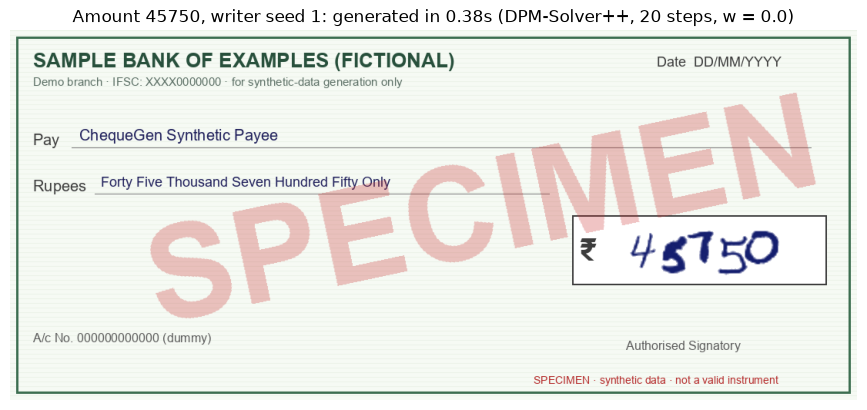

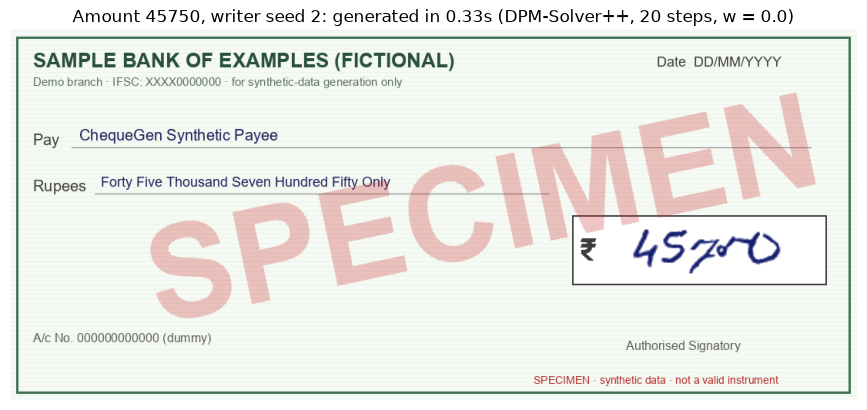

In [22]:
for seed in [1, 2]:
    cheque, secs = generate_cheque(ema, sched, '45750', steps=20, w=BEST_W, seed=seed, device=DEVICE)
    cheque.save(f'figures/cheque_demo_seed{seed}.png')
    plt.figure(figsize=(11, 4.8)); plt.imshow(cheque); plt.axis('off')
    plt.title(f'Amount 45750, writer seed {seed}: generated in {secs:.2f}s (DPM-Solver++, 20 steps, w = {BEST_W})'); plt.show()
torch.save({'ema': ema.state_dict(), 'cfg': CFG, 'losses': losses, 'train_seconds': train_time, 'best_w': BEST_W}, CKPT)

**Interpretation.** The same amount written with two seeds gives two different "writers" while the digits stay correct, so an OCR team can produce unlimited, varied, labelled cheque-amount images. The image is watermarked **SPECIMEN** and uses a fictional bank, so it cannot be mistaken for a real instrument.

**Gradio app:** `python app.py` opens the interactive version, with an amount box, a sampler choice (DDPM / DDIM / DPM-Solver++), a steps slider, a guidance slider and a writer seed.

In [23]:
RUN_DEMO = False          # set True to launch the interactive Gradio app from inside the notebook
if RUN_DEMO:
    import gradio as gr
    def ui(amount, sampler, steps, guidance, seed):
        img, secs = generate_cheque(ema, sched, amount, int(steps), float(guidance), int(seed), DEVICE, sampler)
        return img, f'Generated in {secs:.2f} s'
    gr.Interface(ui, [gr.Textbox('45750', label='Amount (₹)'), gr.Radio(['dpm', 'ddim'], value='dpm', label='Sampler'),
                      gr.Slider(5, 100, 20, step=5, label='Steps'), gr.Slider(0, 4, BEST_W, step=0.5, label='Guidance w'),
                      gr.Number(1, label='Writer seed')],
                 [gr.Image(label='Synthetic SPECIMEN cheque'), gr.Textbox(label='Timing')], title='ChequeGen').launch()

## 11. Summary and conclusions

In [24]:
v1_lims = f"""
| Version-1 limitation | What version 2 did | Result in this run |
|---|---|---|
| Small model, short CPU training | {'GPU: ' + str(RESULTS['gpu']) + ', ' if GPU else 'CPU fallback, '}{n_params:,}-parameter U-Net, {CFG['train_steps']:,} steps{', mixed precision' if CFG['amp'] else ''} | DDPM-1000 FID {b.fid:.1f}; label accuracy {b.label_acc:.1f}% |
| FID from one run of 500 images; FID mixes realism and diversity | {n} images × {CFG['n_seeds']} seeds, mean ± sd; precision/recall added | FID sd ≈ {agg.fid_sd.mean():.2f}; recall exposes the diversity gap ({agg.recall.max():.2f} vs {r_floor:.2f} real) |
| Speed: DDIM still needs about 50 steps | DPM-Solver++(2M), a 2nd-order solver | DPM-Solver++-20: **{p20.speedup:.0f}× faster** (FID {p20.fid:.1f}); DPM-Solver++-5: {p5.speedup:.0f}× (FID {p5.fid:.1f}) |
| Synthetic-only OCR below real data | Guidance tuned for the downstream task (w = {BEST_W}) | reader on synthetic only: {best.ocr_acc:.2f}% vs {acc_real_same_size:.2f}% on real data |
| Unclear practical value | Synthetic data as augmentation for a small real set | {A.acc:.2f}% → **{C.acc:.2f}%** with {int(C.n_synthetic)} synthetic digits added |
| MNIST is not real cheque handwriting | *Not addressed*: needs a cheque-amount dataset (e.g. CAR/LAR) | — |
"""
summary = f"""
### What the project shows
* **DDIM speeds up diffusion sampling without retraining**: {d50.speedup:.0f}× faster at 50 steps, with quality {cmp(d50.fid, b.fid, d50.fid_sd, b.fid_sd)} the 1000-step baseline.
* **DPM-Solver++** pushes this to **{p20.speedup:.0f}× at 20 steps** and **{p5.speedup:.0f}× at 5 steps**, still with one network call per step.
* **Conditioning plus classifier-free guidance** makes the generator controllable: label accuracy {agg.label_acc.min():.1f}–{agg.label_acc.max():.1f}% across samplers.
* **Diversity is the main remaining limitation, not speed**: recall {agg.recall.max():.2f} vs {r_floor:.2f} for real data. Tuning guidance changed synthetic-only OCR accuracy by {best.ocr_acc - v1.ocr_acc:+.2f} points, and adding synthetic digits to a small real set changed accuracy by {C.acc - A.acc:+.2f} points.

### Version-1 limitations and how they were addressed
{v1_lims}

### Remaining limitations and future work
* Train on real handwritten cheque-amount datasets (CAR/LAR) and generate whole amount strings, including commas and ₹.
* Raise diversity further: stochastic DDIM (η > 0), guidance that is strong only at mid-noise levels, or a larger model.
* Distil to 1–4 steps (consistency models) for on-device generation.

### References
1. Ho, Jain & Abbeel (2020). *Denoising Diffusion Probabilistic Models.* NeurIPS.
2. Song, Meng & Ermon (2021). *Denoising Diffusion Implicit Models.* ICLR.
3. Lu et al. (2022). *DPM-Solver++: Fast Solver for Guided Sampling of Diffusion Probabilistic Models.* arXiv:2211.01095.
4. Ho & Salimans (2022). *Classifier-Free Diffusion Guidance.* NeurIPS Workshop.
5. Kynkäänniemi et al. (2019). *Improved Precision and Recall Metric for Assessing Generative Models.* NeurIPS.
6. Heusel et al. (2017). *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium (FID).* NeurIPS.
7. LeCun, Cortes & Burges. *The MNIST database of handwritten digits.*
"""
display(Markdown(summary)); RESULTS['summary_text'] = summary
json.dump(RESULTS, open('results.json', 'w'), indent=1, default=float)
print('All results saved to results.json')


### What the project shows
* **DDIM speeds up diffusion sampling without retraining**: 20× faster at 50 steps, with quality worse than the 1000-step baseline.
* **DPM-Solver++** pushes this to **50× at 20 steps** and **199× at 5 steps**, still with one network call per step.
* **Conditioning plus classifier-free guidance** makes the generator controllable: label accuracy 99.9–100.0% across samplers.
* **Diversity is the main remaining limitation, not speed**: recall 0.75 vs 0.90 for real data. Tuning guidance changed synthetic-only OCR accuracy by +3.43 points, and adding synthetic digits to a small real set changed accuracy by +4.40 points.

### Version-1 limitations and how they were addressed

| Version-1 limitation | What version 2 did | Result in this run |
|---|---|---|
| Small model, short CPU training | GPU: NVIDIA GeForce RTX 4050 Laptop GPU, 3,689,473-parameter U-Net, 20,000 steps, mixed precision | DDPM-1000 FID 13.7; label accuracy 99.9% |
| FID from one run of 500 images; FID mixes realism and diversity | 2000 images × 3 seeds, mean ± sd; precision/recall added | FID sd ≈ 0.37; recall exposes the diversity gap (0.75 vs 0.90 real) |
| Speed: DDIM still needs about 50 steps | DPM-Solver++(2M), a 2nd-order solver | DPM-Solver++-20: **50× faster** (FID 18.1); DPM-Solver++-5: 199× (FID 17.5) |
| Synthetic-only OCR below real data | Guidance tuned for the downstream task (w = 0.0) | reader on synthetic only: 97.37% vs 97.80% on real data |
| Unclear practical value | Synthetic data as augmentation for a small real set | 93.09% → **97.49%** with 5000 synthetic digits added |
| MNIST is not real cheque handwriting | *Not addressed*: needs a cheque-amount dataset (e.g. CAR/LAR) | — |


### Remaining limitations and future work
* Train on real handwritten cheque-amount datasets (CAR/LAR) and generate whole amount strings, including commas and ₹.
* Raise diversity further: stochastic DDIM (η > 0), guidance that is strong only at mid-noise levels, or a larger model.
* Distil to 1–4 steps (consistency models) for on-device generation.

### References
1. Ho, Jain & Abbeel (2020). *Denoising Diffusion Probabilistic Models.* NeurIPS.
2. Song, Meng & Ermon (2021). *Denoising Diffusion Implicit Models.* ICLR.
3. Lu et al. (2022). *DPM-Solver++: Fast Solver for Guided Sampling of Diffusion Probabilistic Models.* arXiv:2211.01095.
4. Ho & Salimans (2022). *Classifier-Free Diffusion Guidance.* NeurIPS Workshop.
5. Kynkäänniemi et al. (2019). *Improved Precision and Recall Metric for Assessing Generative Models.* NeurIPS.
6. Heusel et al. (2017). *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium (FID).* NeurIPS.
7. LeCun, Cortes & Burges. *The MNIST database of handwritten digits.*


All results saved to results.json
